In [ ]:
%pip install -U duckdb
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install groq
%pip install langchain-openai
%pip install langchain-community
%pip install typing-extensions
%pip install ipython

In [1]:
import os
import getpass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Digite sua GROQ_API_KEY: ")
print("✅ GROQ_API_KEY configurada!")

✅ GROQ_API_KEY configurada!


In [ ]:
%pip install -U duckdb groq sqlglot pandas matplotlib ipython



In [ ]:
from __future__ import annotations

import os
import re
from getpass import getpass
from pathlib import Path
from typing import TypedDict

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from groq import Groq
from IPython.display import display
from sqlglot import exp, parse



DB_PATH = Path(
    r"C:\Users\eugen\Desktop\Kiro\clientes_novo.duckdb1"
).expanduser().resolve()

MODEL = "openai/gpt-oss-120b"
MAX_REVISOES = 3


def conectar(db_path: str | Path = DB_PATH):
    return duckdb.connect(
        str(db_path),
        read_only=True,
        config={"enable_external_access": "false"},
    )


def configurar():
    if not DB_PATH.is_file():
        raise FileNotFoundError(
            f"Arquivo DuckDB não encontrado: {DB_PATH}\n"
            "Corrija DB_PATH; o script não cria um banco vazio."
        )
    with conectar() as con:
        columns = con.execute("""
            SELECT column_name, data_type
            FROM information_schema.columns
            WHERE table_schema = 'main' AND table_name = 'clientes'
            ORDER BY ordinal_position
        """).fetchall()
    if not columns:
        raise ValueError(
            f"A tabela main.clientes não foi encontrada em {DB_PATH}."
        )
    print("Banco:", DB_PATH)
    print("Tabela: main.clientes")
    print("Colunas:", ", ".join(c[0] for c in columns))

    chave = os.getenv("GROQ_API_KEY") or getpass("GROQ_API_KEY: ").strip()
    if not chave:
        raise ValueError("Forneça uma chave Groq válida.")
    return Groq(api_key=chave, timeout=30.0, max_retries=1)


class AgentState(TypedDict):
    question: str
    table_schemas: str
    database: str
    sql: str
    reflect: list[str]
    accepted: bool
    revision: int
    max_revision: int
    validation_error: str


client = None


def invoke_model(messages: list[dict[str, str]]) -> str:
    if client is None:
        raise RuntimeError("Execute client = configurar() antes de perguntar.")
    resposta = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        temperature=0,
    )
    content = resposta.choices[0].message.content
    if isinstance(content, str) and content.strip():
        return content.strip()
    if isinstance(content, list):
        partes = [
            bloco.get("text", "") for bloco in content
            if isinstance(bloco, dict) and bloco.get("type") in ("text", "output_text")
        ]
        if any(partes):
            return "\n".join(partes).strip()
    raise ValueError("O modelo não retornou conteúdo textual válido.")


def get_database_schema(db_path: str | Path) -> str:
    with conectar(db_path) as con:
        columns = con.execute("DESCRIBE main.clientes").fetchall()
    return "Tabela: main.clientes\nColunas:\n" + "\n".join(
        f"- {nome} ({tipo})" for nome, tipo, *_ in columns
    )


def search_engineer_node(state: AgentState) -> AgentState:
    return {
        **state,
        "table_schemas": get_database_schema(DB_PATH),
        "database": str(DB_PATH),
    }


def senior_sql_writer_node(state: AgentState) -> AgentState:
    role_prompt = """
Você é um especialista em SQL. Sua tarefa é escrever **apenas** a consulta SQL que responda à pergunta do usuário. A consulta deve:

- Usar a sintaxe SQL padrão em inglês.
- Utilizar os nomes das tabelas e colunas conforme definidos no esquema do banco de dados.
- Não incluir comentários, explicações ou qualquer texto adicional.
- Não utilizar formatação de código ou markdown.
- Retornar apenas a consulta SQL válida.
"""
    instruction = f"Esquema do banco de dados:\n{state['table_schemas']}\n"
    instruction += f"Escreva a consulta SQL que responda à seguinte pergunta: {state['question']}\n"
    messages = [
        {"role": "system", "content": role_prompt},
        {"role": "user", "content": instruction}
    ]
    response = invoke_model(messages)
    return {**state, "sql": response.strip(), "revision": state['revision'] + 1}
    instruction = (
        f"Esquema:\n{state['table_schemas']}\n\n"
        f"Pergunta: {state['question']}\n"
    )
    if state["reflect"]:
        instruction += "\nErros de validação anteriores:\n" + "\n".join(state["reflect"])
    sql = invoke_model([
        {"role": "system", "content": prompt},
        {"role": "user", "content": instruction},
    ])
    sql = re.sub(r"^```(?:sql)?\s*|\s*```$", "", sql.strip(), flags=re.I).strip()
    print(f"\n[SQL Writer] tentativa {state['revision'] + 1}:\n{sql}")
    return {**state, "sql": sql, "revision": state["revision"] + 1}


def validar_sql(sql: str) -> None:
    if sql.upper() == "DADOS_INSUFICIENTES":
        raise ValueError("A pergunta não pode ser respondida com os dados disponíveis.")

    statements = [stmt for stmt in parse(sql, read="duckdb") if stmt is not None]
    if len(statements) != 1 or not isinstance(statements[0], exp.Select):
        raise ValueError("Apenas uma instrução SELECT é permitida.")

    arvore = statements[0]
    if arvore.find(exp.CTE) or arvore.find(exp.Join):
        raise ValueError("Não utilize CTE ou JOIN; consulte main.clientes diretamente.")

    tabelas = list(arvore.find_all(exp.Table))
    if not tabelas:
        raise ValueError("A consulta deve referenciar main.clientes.")
    for tabela in tabelas:
        if (tabela.name.lower() != "clientes"
                or (tabela.db and tabela.db.lower() != "main")
                or tabela.catalog):
            raise ValueError(
                f"Tabela não permitida: {tabela.sql(dialect='duckdb')}. "
                "Use apenas main.clientes."
            )

    # Verifica tabelas e colunas sem executar a consulta.
    with conectar() as con:
        con.execute("EXPLAIN " + sql)


def senior_qa_engineer_node(state: AgentState) -> AgentState:
    try:
        validar_sql(state["sql"])
        print("[QA] SQL aprovado pelo parser e pelo DuckDB.")
        return {**state, "accepted": True, "validation_error": ""}
    except Exception as e:
        erro = str(e)
        print("[QA] SQL rejeitado:", erro)
        return {**state, "accepted": False, "validation_error": erro}


def chief_dba_node(state: AgentState) -> AgentState:
    # Usa o diagnóstico real do DuckDB para orientar a próxima geração.
    return {**state, "reflect": [*state["reflect"], state["validation_error"]]}


def execute_query(state: AgentState) -> pd.DataFrame:
    if not state["accepted"]:
        raise ValueError("A consulta foi rejeitada e não pode ser executada.")
    with conectar() as con:
        return con.execute(state["sql"]).df()


def interpret_results(question: str, sql: str, resultado: pd.DataFrame) -> str:
    if resultado.empty:
        return "A consulta foi válida, mas não retornou linhas."
    resumo = resultado.head(20).to_string(index=False)
    return invoke_model([
        {"role": "system", "content": (
            "Interprete os resultados sem inventar informações. "
            "Responda de forma concisa em português. "
            "Balance é saldo, não pagamento. "
            "Use apenas os dados fornecidos."
        )},
        {"role": "user", "content": (
            f"Pergunta: {question}\nSQL: {sql}\n"
            f"Linhas retornadas: {len(resultado)}\n"
            f"Amostra (até 20 linhas):\n{resumo}"
        )},
    ])


def plot_results(question: str, resultado: pd.DataFrame) -> None:
    if len(resultado) <= 1 or len(resultado.columns) != 2:
        print("Nenhum gráfico necessário.")
        return
    x, y = resultado.columns
    if not pd.api.types.is_numeric_dtype(resultado[y]):
        print("Nenhum gráfico necessário.")
        return
    plt.figure(figsize=(9, 5))
    plt.bar(resultado[x].astype(str), resultado[y].astype(float))
    plt.title(question)
    plt.xlabel(str(x))
    plt.ylabel(str(y))
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()


def process_question(question: str) -> dict:
    state: AgentState = {
        "question": question,
        "table_schemas": "",
        "database": "",
        "sql": "",
        "reflect": [],
        "accepted": False,
        "revision": 0,
        "max_revision": MAX_REVISOES,
        "validation_error": "",
    }
    state = search_engineer_node(state)

    for _ in range(state["max_revision"]):
        state = senior_sql_writer_node(state)
        if state["sql"].upper() == "DADOS_INSUFICIENTES":
            print("Pergunta não respondível com o esquema de main.clientes.")
            return {"state": state, "data": None}
        state = senior_qa_engineer_node(state)
        if state["accepted"]:
            break
        state = chief_dba_node(state)

    if not state["accepted"]:
        print("Consulta rejeitada após todas as tentativas:")
        print(state["validation_error"])
        return {"state": state, "data": None}

    try:
        resultado = execute_query(state)
    except duckdb.Error as exc:
        print("Falha ao executar a consulta validada:", exc)
        return {"state": state, "data": None}

    print("\nResultados da consulta:")
    display(resultado)
    print("\nInterpretação:")
    try:
        print(interpret_results(question, state["sql"], resultado))
    except Exception as exc:
        print("Não foi possível interpretar automaticamente:", exc)
    plot_results(question, resultado)
    return {"state": state, "data": resultado}


In [3]:
client = configurar()

Banco: C:\Users\eugen\Desktop\Kiro\clientes_novo.duckdb1
Tabela: main.clientes
Colunas: cliente_id, nome, sobrenome, email, produto, plano, valor_pago


In [4]:
from pathlib import Path

DB_PATH = Path(
    r"C:\Users\eugen\Desktop\Kiro\clientes_novo.duckdb"
).expanduser().resolve()

client = configurar()

print("Cliente Groq configurado!")
print("Banco utilizado:", DB_PATH)

Banco: C:\Users\eugen\Desktop\Kiro\clientes_novo.duckdb
Tabela: main.clientes
Colunas: cliente_id, nome, sobrenome, email, produto, plano, valor_pago
Cliente Groq configurado!
Banco utilizado: C:\Users\eugen\Desktop\Kiro\clientes_novo.duckdb


[QA] SQL aprovado pelo parser e pelo DuckDB.

Resultados da consulta:


,produto,quantidade
0,Produto D,2
1,Produto E,2
2,Produto A,1
3,Produto C,1
4,Produto B,1
5,Produto F,1



Interpretação:
A distribuição do número de produtos é:

- Produto D: 2 ocorrências  
- Produto E: 2 ocorrências  
- Produto A: 1 ocorrência  
- Produto C: 1 ocorrência  
- Produto B: 1 ocorrência  
- Produto F: 1 ocorrência  

Total de linhas retornadas: 6.


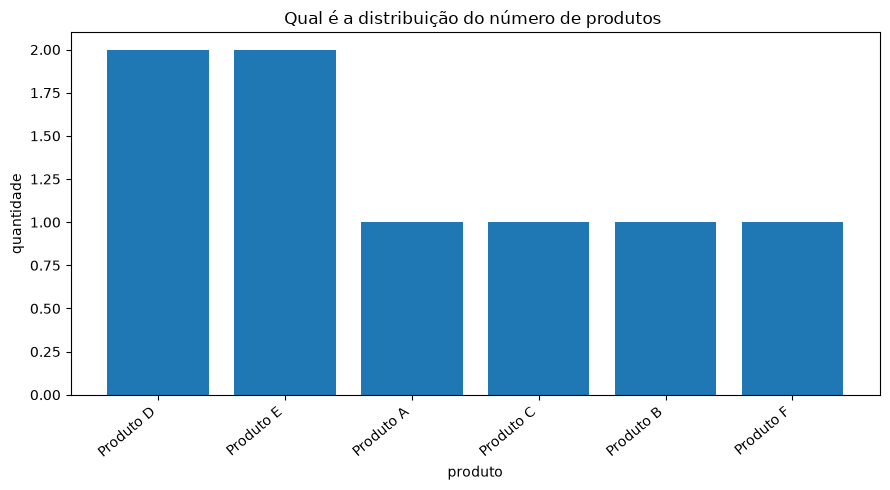

In [6]:
question = (
    "Qual é a distribuição do número de produtos "
    
)

resultado = process_question(question)

[QA] SQL aprovado pelo parser e pelo DuckDB.

Resultados da consulta:


,produto,preco_minimo
0,Produto F,900.0
1,Produto D,900.0
2,Produto E,900.0
3,Produto C,900.0
4,Produto B,900.0
5,Produto A,10000.0



Interpretação:
**Produtos mais baratos (preço mínimo):**

| Produto | Preço mínimo |
|---------|--------------|
| Produto F | R$ 900,00 |
| Produto D | R$ 900,00 |
| Produto E | R$ 900,00 |
| Produto C | R$ 900,00 |
| Produto B | R$ 900,00 |
| Produto A | R$ 10.000,00 |

**Gráfico de barras (texto)** – o comprimento da barra representa o preço (escala simplificada):

```
Produto F ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 900
Produto D ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 900
Produto E ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 900
Produto C ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 900
Produto B ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 900
Produto A ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

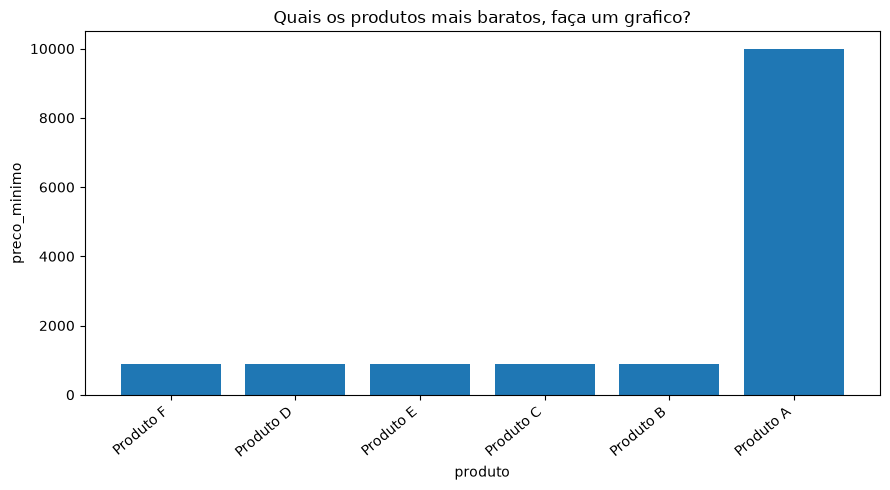

{'state': {'question': 'Quais os produtos mais baratos, faça um grafico?',
  'table_schemas': 'Tabela: main.clientes\nColunas:\n- cliente_id (INTEGER)\n- nome (VARCHAR)\n- sobrenome (VARCHAR)\n- email (VARCHAR)\n- produto (VARCHAR)\n- plano (VARCHAR)\n- valor_pago (DECIMAL(10,2))',
  'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo.duckdb',
  'sql': 'SELECT produto, MIN(valor_pago) AS preco_minimo\nFROM main.clientes\nGROUP BY produto\nORDER BY preco_minimo ASC',
  'reflect': [],
  'accepted': True,
  'revision': 1,
  'max_revision': 3,
  'validation_error': ''},
 'data':      produto  preco_minimo
 0  Produto F         900.0
 1  Produto D         900.0
 2  Produto E         900.0
 3  Produto C         900.0
 4  Produto B         900.0
 5  Produto A       10000.0}

In [8]:
question = "Quais os produtos mais baratos, faça um grafico?"
process_question(question)

[QA] SQL aprovado pelo parser e pelo DuckDB.

Resultados da consulta:


,produto,max_valor
0,Produto A,10000.0
1,Produto D,10000.0
2,Produto E,10000.0
3,Produto B,900.0
4,Produto C,900.0
5,Produto F,900.0



Interpretação:
**Gráfico sugerido:** barra horizontal (ou vertical) com o valor máximo pago por produto.

| Produto | Valor máximo (R$) |
|---------|-------------------|
| Produto A | 10 000 |
| Produto D | 10 000 |
| Produto E | 10 000 |
| Produto B |   900 |
| Produto C |   900 |
| Produto F |   900 |

**Como montar o gráfico**

1. **Eixo X (ou Y)** – valor máximo (R$).  
2. **Eixo Y (ou X)** – nomes dos produtos.  
3. Ordene as barras do maior para o menor valor (já está em ordem decrescente).  
4. Destaque as três primeiras barras (10 000) para evidenciar os produtos mais caros.

Esse gráfico mostrará claramente que *Produto A, Produto D* e *Produto E* são os mais caros, com valor máximo de **R$ 10 000**, enquanto os demais atingem **R$ 900**.


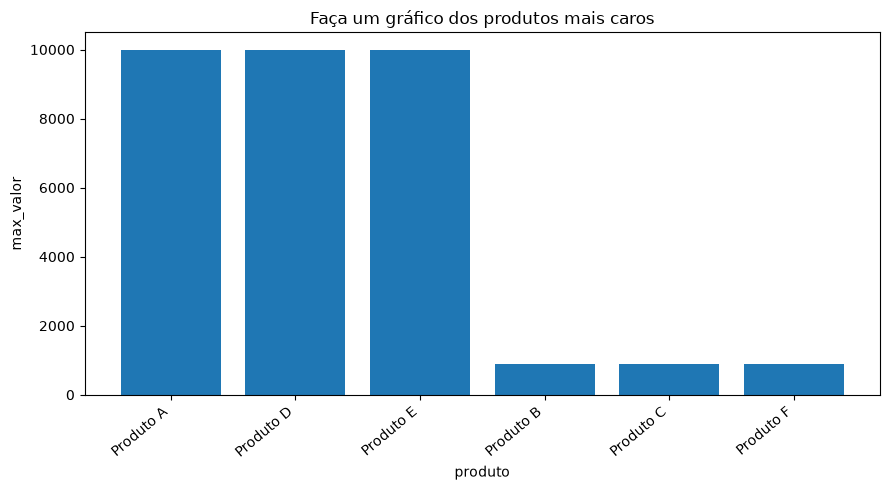

{'state': {'question': 'Faça um gráfico dos produtos mais caros',
  'table_schemas': 'Tabela: main.clientes\nColunas:\n- cliente_id (INTEGER)\n- nome (VARCHAR)\n- sobrenome (VARCHAR)\n- email (VARCHAR)\n- produto (VARCHAR)\n- plano (VARCHAR)\n- valor_pago (DECIMAL(10,2))',
  'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo.duckdb',
  'sql': 'SELECT produto, MAX(valor_pago) AS max_valor\nFROM main.clientes\nGROUP BY produto\nORDER BY max_valor DESC;',
  'reflect': [],
  'accepted': True,
  'revision': 1,
  'max_revision': 3,
  'validation_error': ''},
 'data':      produto  max_valor
 0  Produto A    10000.0
 1  Produto D    10000.0
 2  Produto E    10000.0
 3  Produto B      900.0
 4  Produto C      900.0
 5  Produto F      900.0}

In [10]:
question = "Faça um gráfico dos produtos mais caros"
process_question(question)

In [11]:
question = "Qual é o produto mais popular entre os clientes?"
process_question(question)

[QA] SQL aprovado pelo parser e pelo DuckDB.

Resultados da consulta:


,produto
0,Produto D



Interpretação:
O produto mais popular entre os clientes é **Produto D**.
Nenhum gráfico necessário.


{'state': {'question': 'Qual é o produto mais popular entre os clientes?',
  'table_schemas': 'Tabela: main.clientes\nColunas:\n- cliente_id (INTEGER)\n- nome (VARCHAR)\n- sobrenome (VARCHAR)\n- email (VARCHAR)\n- produto (VARCHAR)\n- plano (VARCHAR)\n- valor_pago (DECIMAL(10,2))',
  'database': 'C:\\Users\\eugen\\Desktop\\Kiro\\clientes_novo.duckdb',
  'sql': 'SELECT produto FROM main.clientes GROUP BY produto ORDER BY COUNT(*) DESC LIMIT 1',
  'reflect': [],
  'accepted': True,
  'revision': 1,
  'max_revision': 3,
  'validation_error': ''},
 'data':      produto
 0  Produto D}